# 02 · Curation: QC, normalization, gene selection, gene-space alignment

This notebook walks the curation path a training run takes
(`SingleCellDataModule.setup`) one method at a time, and after each step
measures what changed in the data:

1. **Quality control** – which cells and genes are dropped, and how sensitive
   that is to the thresholds
2. **Raw-count guard** – detecting normalized input before it reaches a
   count likelihood
3. **Normalization** – what CP10K and `log1p` each do to depth dependence
   and to the mean–variance relation
4. **Highly variable genes** – pooled versus batch-aware selection
5. **Gene vocabulary and harmonization** – aligning a dataset with a
   different gene panel, and what missing genes cost
6. **Stage-by-stage summary** – one table of how the data's characteristics
   move through the whole path

Methods are imported from `src/data/preprocessing.py`; nothing is
reimplemented here.

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from IPython.display import display

from nbutils import (set_style, load_data, describe, pca, r2_by_group, codes, probe_f1,
                     label_bars, SERIES, BLUE, ORANGE, AQUA, NEUTRAL, MUTED, SURFACE, INK)
from src.data.preprocessing import (normalize_counts, select_hvg, is_raw_counts,
                                    GeneVocabulary, harmonize_genes)
from src.data.splits import DonorHeldOutSplitter
from src.eval.metrics import pcr_batch, library_size_leakage, evaluate_embedding

set_style()

In [2]:
DATA_PATH = None        # e.g. "/path/to/dataset.h5ad"
OBS_MAP   = None
RAW_LAYER = None

adata = load_data(DATA_PATH, OBS_MAP, RAW_LAYER, n_cells=3000, n_genes=2000, seed=0)
IS_SYNTHETIC = bool(adata.uns.get("synthetic", False))
X_raw = sp.csr_matrix(adata.X)
obs_raw = adata.obs.reset_index(drop=True)
pd.DataFrame([describe(X_raw, "raw")]).set_index("stage")

,cells,genes,sparsity_%,median_depth,median_genes_per_cell
stage,,,,,
raw,3000,2000,86.8,5538.5,259


## 1 · Quality control

Two filters run before anything else, because neither depends on labels:

- `min_genes_per_cell` removes empty droplets and dead cells
- `min_cells_per_gene` removes genes observed too rarely to estimate anything

The dashed lines mark the thresholds this notebook applies. The lower panels
show how much data survives as each threshold moves, which is the thing to
check before copying a threshold from another dataset.

dropped 0 cells and 464 genes; 0.003% of all UMIs removed


,cells,genes,sparsity_%,median_depth,median_genes_per_cell
stage,,,,,
raw,3000,2000,86.8,5538.5,259
after QC,3000,1536,82.9,5538.5,259


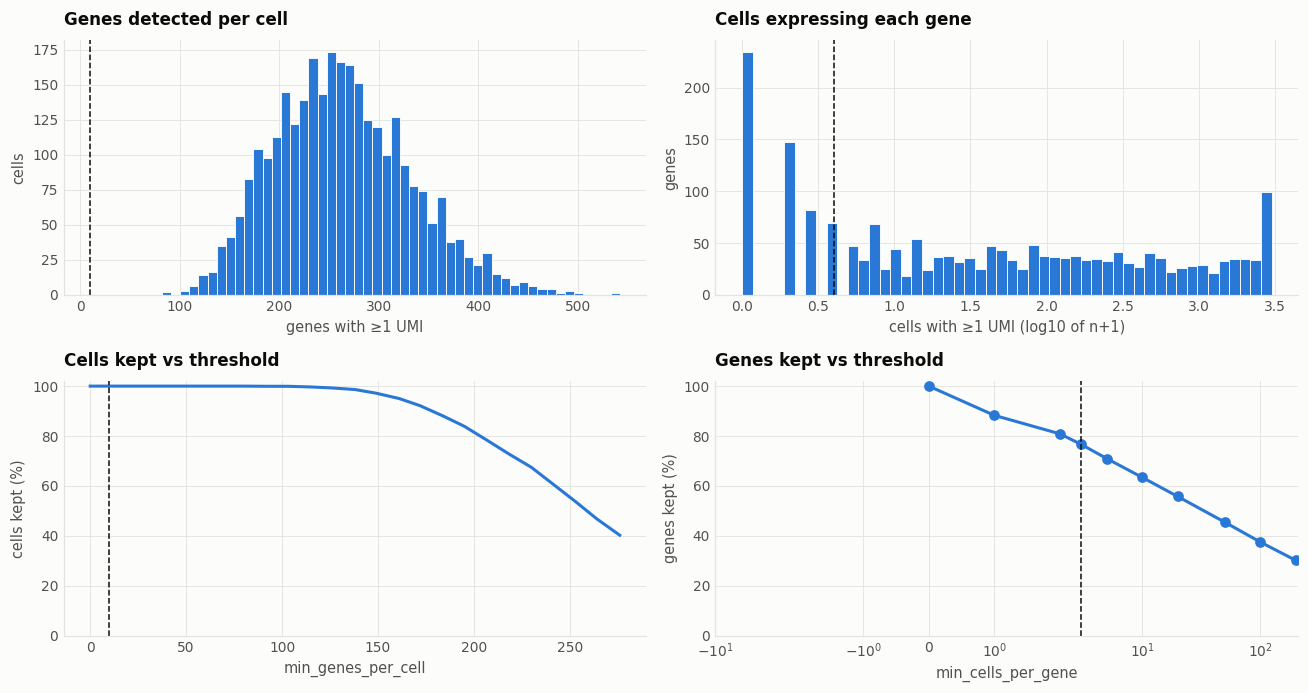

In [3]:
MIN_GENES_PER_CELL = 10       # repo default for synthetic; ~200 is usual for 10x data
MIN_CELLS_PER_GENE = 3

genes_per_cell = np.diff(X_raw.indptr)
cells_per_gene = np.asarray((X_raw > 0).sum(0)).ravel()

cell_thr = np.unique(np.linspace(0, np.percentile(genes_per_cell, 60), 25).astype(int))
gene_thr = np.array([0, 1, 2, 3, 5, 10, 20, 50, 100, 200])

fig, ax = plt.subplots(2, 2, figsize=(12, 6.4))
ax[0, 0].hist(genes_per_cell, bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax[0, 0].axvline(MIN_GENES_PER_CELL, color=INK, linestyle="--", linewidth=1)
ax[0, 0].set(title="Genes detected per cell", xlabel="genes with ≥1 UMI", ylabel="cells")
ax[0, 1].hist(np.log10(cells_per_gene + 1), bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax[0, 1].axvline(np.log10(MIN_CELLS_PER_GENE + 1), color=INK, linestyle="--", linewidth=1)
ax[0, 1].set(title="Cells expressing each gene", xlabel="cells with ≥1 UMI (log10 of n+1)", ylabel="genes")
ax[1, 0].plot(cell_thr, [100 * (genes_per_cell >= t).mean() for t in cell_thr], color=BLUE)
ax[1, 0].axvline(MIN_GENES_PER_CELL, color=INK, linestyle="--", linewidth=1)
ax[1, 0].set(title="Cells kept vs threshold", xlabel="min_genes_per_cell", ylabel="cells kept (%)", ylim=(0, 102))
ax[1, 1].plot(gene_thr, [100 * (cells_per_gene >= t).mean() for t in gene_thr], marker="o", color=BLUE)
ax[1, 1].axvline(MIN_CELLS_PER_GENE, color=INK, linestyle="--", linewidth=1)
ax[1, 1].set(title="Genes kept vs threshold", xlabel="min_cells_per_gene", ylabel="genes kept (%)",
             xscale="symlog", ylim=(0, 102))
fig.tight_layout()

keep_cells = genes_per_cell >= MIN_GENES_PER_CELL
keep_genes = cells_per_gene >= MIN_CELLS_PER_GENE
X = X_raw[keep_cells][:, keep_genes].tocsr()
obs = obs_raw.loc[keep_cells].reset_index(drop=True)
gene_names = adata.var_names.to_numpy()[keep_genes]

lost = 1 - X.sum() / X_raw.sum()
print(f"dropped {(~keep_cells).sum()} cells and {(~keep_genes).sum()} genes; "
      f"{100 * lost:.3f}% of all UMIs removed")
pd.DataFrame([describe(X_raw, "raw"), describe(X, "after QC")]).set_index("stage")

Dropped genes are numerous but carry almost no molecules, so QC changes the
matrix's shape far more than its content.

## 2 · Raw-count guard

Public `.h5ad` files often hold normalized values in `.X` and keep the counts
in a layer. Feeding normalized values to a count likelihood is silent and
wrong. `is_raw_counts` is the check `H5ADSource` uses to refuse such input.

In [4]:
Xn_demo, _ = normalize_counts(X)
print("raw matrix            ->", is_raw_counts(X))
print("log1p(CP10K) matrix   ->", is_raw_counts(Xn_demo))
print("CP10K without log     ->", is_raw_counts(normalize_counts(X, log1p=False)[0]))

raw matrix            -> True
log1p(CP10K) matrix   -> False
CP10K without log     -> False


## 3 · Normalization

`normalize_counts` does two separate things:

- **Depth scaling** (counts per 10,000) divides each cell by its library
  size, removing the factor that says "this cell was sequenced more".
- **`log1p`** compresses the scale so a handful of highly expressed genes no
  longer dominate the variance.

The panels measure each one's effect on a 20-component PCA: how much of the
embedding is explained by depth, by batch, and by cell type.

,depth R²,batch (PCR),cell type R² (top-10 PCs)
representation,,,
raw counts,0.877,0.171,0.206
log1p only,0.978,0.344,0.326
CP10K only,0.259,0.207,0.292
CP10K + log1p,0.757,0.363,0.332


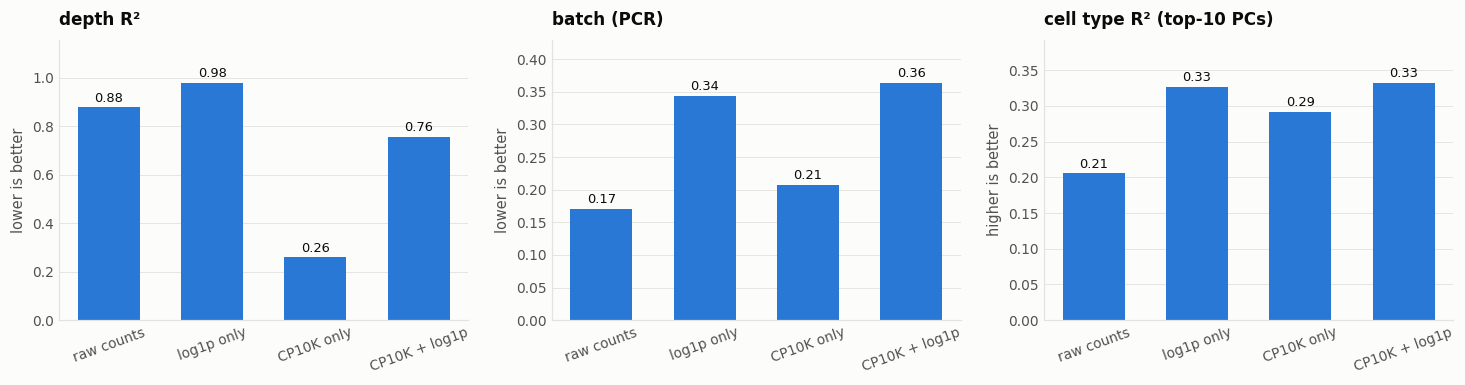

In [5]:
lib = np.asarray(X.sum(1)).ravel()
cp10k = normalize_counts(X, log1p=False)[0]
lognorm = normalize_counts(X, log1p=True)[0]
log_raw = X.copy().astype(np.float32); log_raw.data = np.log1p(log_raw.data)

reps = {"raw counts": X.astype(np.float32), "log1p only": log_raw, "CP10K only": cp10k, "CP10K + log1p": lognorm}
rows = []
for name, M in reps.items():
    Z = pca(M, k=20)
    rows.append({
        "representation": name,
        "depth R²": library_size_leakage(Z, lib),
        "batch (PCR)": pcr_batch(Z, obs["batch_id"]),
        "cell type R² (top-10 PCs)": float(r2_by_group(Z[:, :10], obs["cell_type"]).mean()),
    })
norm_df = pd.DataFrame(rows).set_index("representation")

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6))
for a, col, note in zip(ax, norm_df.columns, ["lower is better", "lower is better", "higher is better"]):
    bars = a.bar(norm_df.index, norm_df[col], color=BLUE, width=0.6)
    a.set(title=col, ylabel=note, ylim=(0, max(norm_df[col].max() * 1.18, 0.05)))
    a.tick_params(axis="x", rotation=20)
    a.grid(axis="x", visible=False)
    label_bars(a, bars)
fig.tight_layout()
norm_df.round(3)

**Reading it.** Compare *raw counts* with *CP10K only* to see what depth
scaling does, and *CP10K only* with *CP10K + log1p* to see what the log adds.

Depth scaling removes most of the depth signal. The log then raises
cell-type signal, but it can also bring depth back: after scaling, a shallow
cell still has more zeros than a deep one, and its few non-zero values are
scaled up. On a log scale that pattern is easy to tell apart, so the
embedding can read depth off the zero/non-zero structure. If the last bar in
the left panel is well above the third, that is what is happening in your
data.

This is why the repo's evaluation panel always reports `library_size_r2`,
and it is one motivation for the depth-invariant tokenizers in notebook 04.

The second view is the mean–variance relation. Before `log1p`, variance
grows with the square of the mean, so the most abundant genes own the
variance budget. After it, the relation flattens.

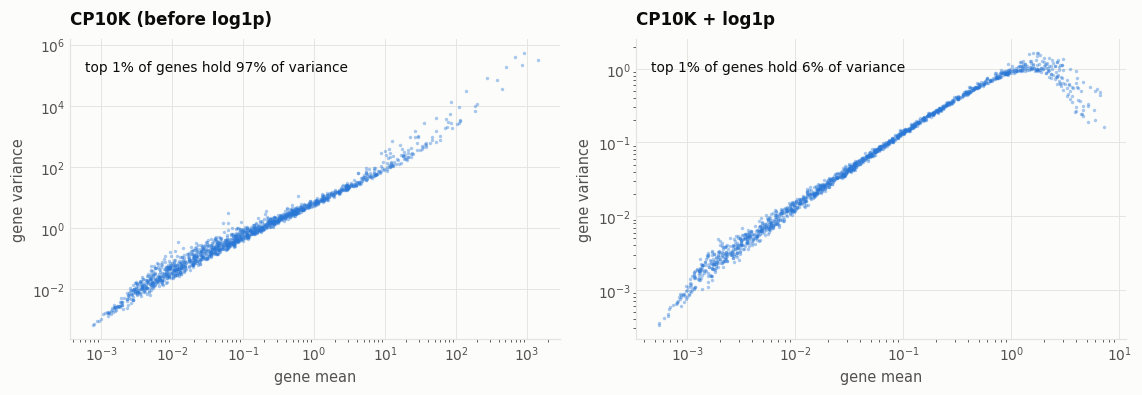

In [6]:
def mean_var(M):
    m = np.asarray(M.mean(0)).ravel()
    v = np.asarray(M.multiply(M).mean(0)).ravel() - m ** 2
    return m, v

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.7))
for a, (name, M) in zip(ax, [("CP10K (before log1p)", cp10k), ("CP10K + log1p", lognorm)]):
    m, v = mean_var(M)
    ok = (m > 0) & (v > 0)
    a.scatter(m[ok], v[ok], s=5, color=BLUE, alpha=0.4, linewidths=0)
    a.set(title=name, xlabel="gene mean", ylabel="gene variance", xscale="log", yscale="log")
    top = np.sort(v)[::-1]
    a.text(0.03, 0.93, f"top 1% of genes hold {100 * top[: max(1, len(top) // 100)].sum() / top.sum():.0f}% of variance",
           transform=a.transAxes, fontsize=9, color=INK, va="top")
fig.tight_layout()

`log1p` is not scale-invariant: `log1p(x·s)` depends on `s`, so the choice of
`target_sum` changes how zeros relate to non-zeros. The sweep shows how much
that choice matters for this dataset.

median library size: 5538  (dashed line = the repo default, 10,000)


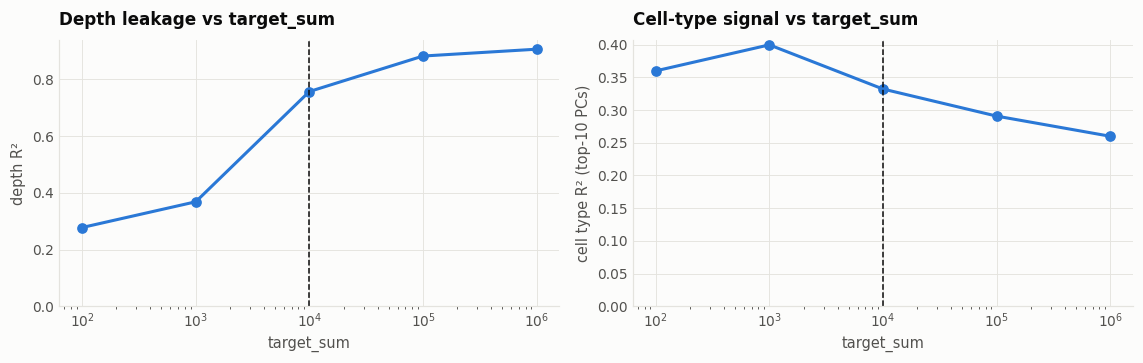

In [7]:
targets = [1e2, 1e3, 1e4, 1e5, 1e6]
sweep = []
for t in targets:
    Z = pca(normalize_counts(X, target_sum=t)[0], k=20)
    sweep.append((library_size_leakage(Z, lib), float(r2_by_group(Z[:, :10], obs["cell_type"]).mean())))
sweep = np.array(sweep)

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4))
ax[0].plot(targets, sweep[:, 0], marker="o", color=BLUE)
ax[0].set(title="Depth leakage vs target_sum", xscale="log", xlabel="target_sum", ylabel="depth R²", ylim=(0, None))
ax[1].plot(targets, sweep[:, 1], marker="o", color=BLUE)
ax[1].set(title="Cell-type signal vs target_sum", xscale="log", xlabel="target_sum",
          ylabel="cell type R² (top-10 PCs)", ylim=(0, None))
for a in ax:
    a.axvline(1e4, color=INK, linestyle="--", linewidth=1)
fig.tight_layout()
print(f"median library size: {np.median(lib):.0f}  (dashed line = the repo default, 10,000)")

## 4 · Highly variable genes

`select_hvg` keeps the `n_top` genes that vary most, working on raw counts.
Two choices define it:

**How "variable" is scored (`flavor`)**
- `dispersion` – variance / mean. Under negative-binomial noise this ratio
  grows with the mean, so it favours abundant genes.
- `pearson_residuals` (repo default) – variance of each gene's residuals
  from a depth-only negative-binomial null. A gene scores highly only when
  it varies more than depth and count noise predict.

**Where the ranking is done (`batch`)**
- pooled – once over all cells
- batch-aware – within each batch, ranks averaged, so a gene that differs
  *between* batches but is flat inside each is not counted as variable

The panels compare three strategies on the same data.

genes shared between strategies (of 250):


,dispersion pooled,Pearson pooled,Pearson batch-aware
dispersion pooled,250,175,180
Pearson pooled,175,250,193
Pearson batch-aware,180,193,250


,true program genes (%),median cell-type R²,median batch R²,share of all UMIs (%)
dispersion pooled,39.600,0.028,0.069,95.495003
Pearson pooled,45.600,0.040,0.060,94.580002
Pearson batch-aware,42.800,0.043,0.063,95.835999
all genes,25.846,0.004,0.004,100.000000


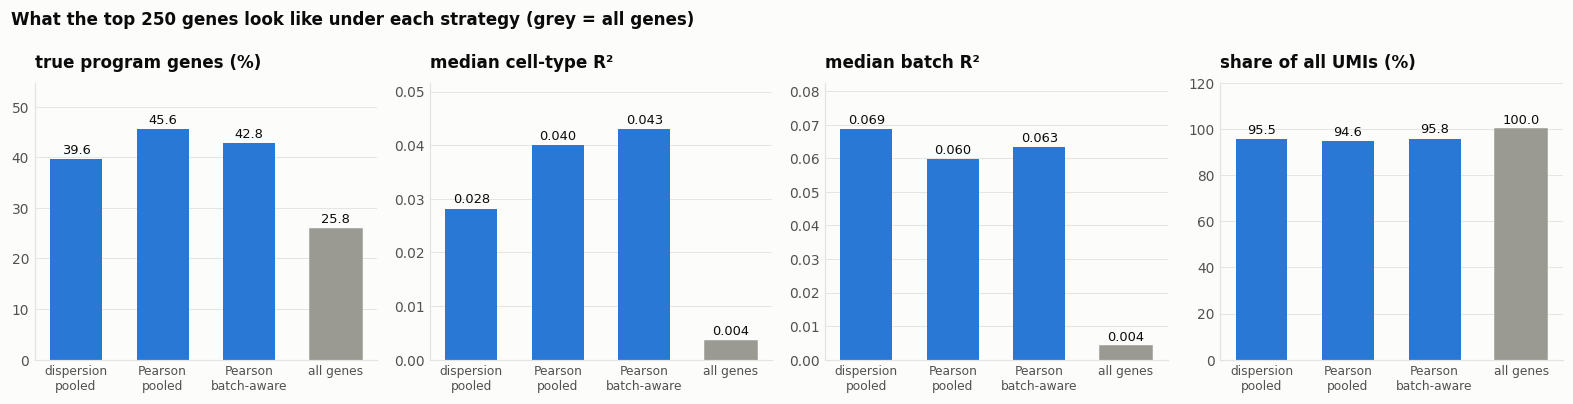

In [8]:
N_TOP = 250
batch = obs["batch_id"].astype(str).to_numpy()
strategies = {
    "dispersion\npooled": dict(flavor="dispersion"),
    "Pearson\npooled": dict(flavor="pearson_residuals"),
    "Pearson\nbatch-aware": dict(flavor="pearson_residuals", batch=batch),
}
selected = {name: select_hvg(X, n_top=N_TOP, **kw) for name, kw in strategies.items()}

dense_ln = np.asarray(lognorm.todense())
gene_batch_r2 = r2_by_group(dense_ln, batch)
gene_type_r2 = r2_by_group(dense_ln, obs["cell_type"])
gene_umis = np.asarray(X.sum(0)).ravel()
gene_mean = gene_umis / X.shape[0]

groups = {**selected, "all genes": np.arange(X.shape[1])}
hvg_table = pd.DataFrame({
    "median cell-type R²": {k: np.median(gene_type_r2[v]) for k, v in groups.items()},
    "median batch R²": {k: np.median(gene_batch_r2[v]) for k, v in groups.items()},
    "share of all UMIs (%)": {k: 100 * gene_umis[v].sum() / gene_umis.sum() for k, v in groups.items()},
})
if IS_SYNTHETIC and "is_marker" in adata.var:
    marker = adata.var["is_marker"].to_numpy()[keep_genes]
    hvg_table.insert(0, "true program genes (%)", {k: 100 * marker[v].mean() for k, v in groups.items()})

fig, ax = plt.subplots(1, hvg_table.shape[1], figsize=(3.6 * hvg_table.shape[1], 3.7))
for a, col in zip(ax, hvg_table.columns):
    bars = a.bar(hvg_table.index, hvg_table[col], color=BLUE, width=0.6)
    bars[-1].set_color(NEUTRAL)                      # reference: no selection
    a.set(title=col, ylim=(0, hvg_table[col].max() * 1.2 + 1e-9))
    a.grid(axis="x", visible=False)
    a.tick_params(axis="x", labelsize=8)
    label_bars(a, bars, fmt="{:.1f}" if "%" in col else "{:.3f}")
fig.suptitle(f"What the top {N_TOP} genes look like under each strategy (grey = all genes)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()

names = list(selected)
overlap = pd.DataFrame([[len(np.intersect1d(selected[a], selected[b])) for b in names] for a in names],
                       index=[n.replace("\n", " ") for n in names], columns=[n.replace("\n", " ") for n in names])
print(f"genes shared between strategies (of {N_TOP}):")
display(overlap)
hvg_table.rename(index=lambda s: s.replace("\n", " ")).round(3)

A selection that simply tracks abundance shows up as a distribution shifted
to the right of the "all genes" curve, with nothing chosen from the middle
of the expression range.

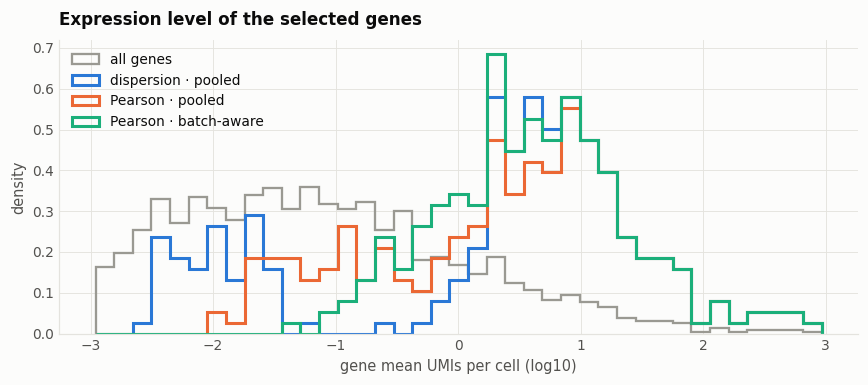

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
logm = np.log10(gene_mean + 1e-4)
bins = np.linspace(logm.min(), logm.max(), 40)
ax.hist(logm, bins=bins, density=True, histtype="step", linewidth=1.5, color=NEUTRAL, label="all genes")
for (name, idx), color in zip(selected.items(), [BLUE, ORANGE, AQUA]):
    ax.hist(logm[idx], bins=bins, density=True, histtype="step", linewidth=2, color=color,
            label=name.replace("\n", " · "))
ax.set(title="Expression level of the selected genes", xlabel="gene mean UMIs per cell (log10)", ylabel="density")
ax.legend(loc="upper left")
fig.tight_layout()

hvg_batch = select_hvg(X, n_top=500, batch=batch)      # the repo default, used below

**How many genes?** The sweep selects genes on the training donors only,
builds a PCA on them, and scores two things on held-out donors: a
logistic-regression probe for cell type, and how much of the embedding batch
explains. The right-most point uses every gene.

,dispersion · pooled F1,Pearson · pooled F1,Pearson · batch-aware F1,dispersion · pooled PCR,Pearson · pooled PCR,Pearson · batch-aware PCR
50,0.859,0.866,0.868,0.168,0.157,0.122
100,0.870,0.884,0.878,0.213,0.214,0.190
250,0.877,0.902,0.888,0.283,0.261,0.258
500,0.889,0.888,0.888,0.294,0.288,0.298
1000,0.892,0.884,0.879,0.301,0.301,0.301
1500,0.888,0.888,0.877,0.301,0.301,0.301
1536,0.881,0.881,0.881,0.301,0.301,0.301


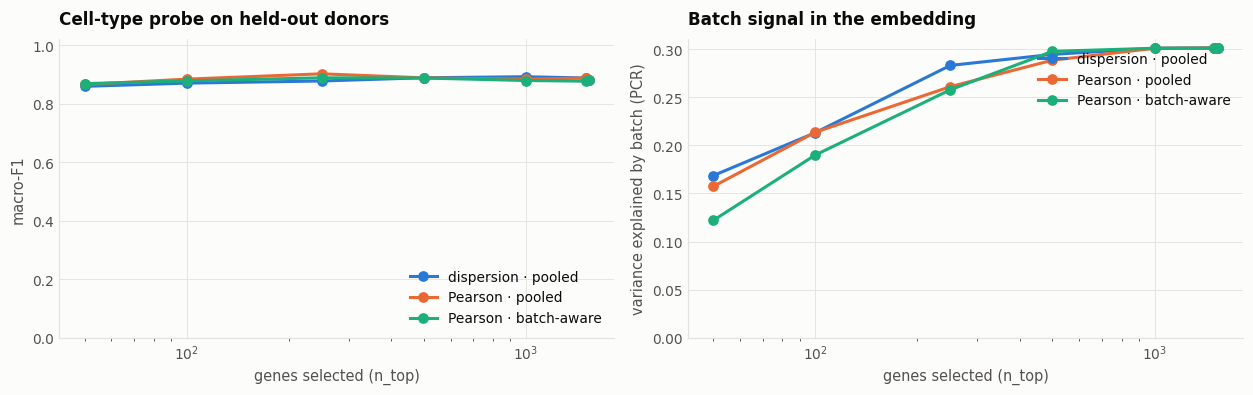

In [10]:
split = DonorHeldOutSplitter(val=0.15, test=0.25, seed=0).split(obs)
tr, te = np.concatenate([split["train"], split["val"]]), split["test"]
y = codes(obs["cell_type"])
n_all = X.shape[1]
sizes = [n for n in [50, 100, 250, 500, 1000, 1500] if n < n_all] + [n_all]

res = {"dispersion · pooled": [], "Pearson · pooled": [], "Pearson · batch-aware": []}
for n in sizes:
    for mode in res:
        idx = select_hvg(X[tr], n_top=n,
                         flavor="dispersion" if mode.startswith("dispersion") else "pearson_residuals",
                         batch=batch[tr] if mode.endswith("batch-aware") else None)
        Ztr, Zte = pca(lognorm[tr][:, idx], lognorm[te][:, idx], k=30)
        res[mode].append((probe_f1(Ztr, y[tr], Zte, y[te]), pcr_batch(Zte, batch[te])))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.7))
for (mode, vals), color in zip(res.items(), [BLUE, ORANGE, AQUA]):
    vals = np.array(vals)
    ax[0].plot(sizes, vals[:, 0], marker="o", color=color, label=mode)
    ax[1].plot(sizes, vals[:, 1], marker="o", color=color, label=mode)
ax[0].set(title="Cell-type probe on held-out donors", xlabel="genes selected (n_top)",
          ylabel="macro-F1", xscale="log", ylim=(0, 1.02))
ax[1].set(title="Batch signal in the embedding", xlabel="genes selected (n_top)",
          ylabel="variance explained by batch (PCR)", xscale="log", ylim=(0, None))
ax[0].legend(loc="lower right"); ax[1].legend(loc="upper right")
fig.tight_layout()
pd.DataFrame({f"{m} F1": np.array(v)[:, 0] for m, v in res.items()} |
             {f"{m} PCR": np.array(v)[:, 1] for m, v in res.items()}, index=sizes).round(3)

## 5 · Gene vocabulary and harmonization

A model's token ids must mean the same gene in every dataset.
`GeneVocabulary` freezes the mapping (ids 0–2 are PAD, MASK, CLS), and
`harmonize_genes` reindexes any dataset onto it: genes the dataset lacks
become structural zeros and the coverage fraction is reported.

In [11]:
vocab = GeneVocabulary(gene_names[hvg_batch])
print(vocab, "| first gene id:", vocab.ids([vocab.genes[0]])[0], "| unknown gene ->", vocab.ids(["NOT_A_GENE"])[0])

import anndata as ad
rng = np.random.default_rng(0)

def panel_subset(frac):
    """A dataset measured on a different, shuffled gene panel."""
    keep = np.sort(rng.choice(len(gene_names), int(frac * len(gene_names)), replace=False))
    order = rng.permutation(keep)
    return ad.AnnData(X=X[:, order].copy(), var=pd.DataFrame(index=gene_names[order]))

other = panel_subset(0.7)
X_aligned, coverage = harmonize_genes(other, vocab)
present = vocab.contains(other.var_names)        # which of the other panel's genes are in the vocab
in_other = np.isin(vocab.genes, other.var_names)
same = (X_aligned[:, in_other] != X[:, hvg_batch][:, in_other]).nnz == 0
print(f"coverage of the vocabulary: {coverage:.1%}")
print("shape after harmonization:", X_aligned.shape, "| shared genes identical to the source:", same)
print("columns for absent genes are all zero:", X_aligned[:, ~in_other].nnz == 0)

GeneVocabulary(n_genes=500, vocab_size=503) | first gene id: 3 | unknown gene -> -1
coverage of the vocabulary: 67.0%
shape after harmonization: (3000, 500) | shared genes identical to the source: True
columns for absent genes are all zero: True


Coverage is not a formality. The sweep fits a PCA on the full vocabulary,
then embeds held-out donors measured on progressively smaller panels.

only 30.0% of the model's gene vocabulary is present in this dataset; embeddings are not comparable to the pretraining corpus.


only 15.0% of the model's gene vocabulary is present in this dataset; embeddings are not comparable to the pretraining corpus.


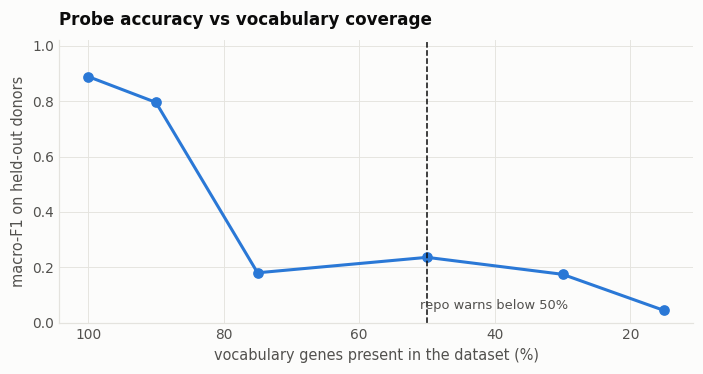

In [12]:
Xv = X[:, hvg_batch]
ln_full = normalize_counts(Xv)[0]
fracs = [1.0, 0.9, 0.75, 0.5, 0.3, 0.15]
cov, f1 = [], []
for f in fracs:
    keep = np.sort(rng.choice(len(vocab.genes), int(f * len(vocab.genes)), replace=False))
    sub = ad.AnnData(X=Xv[:, keep].copy(), var=pd.DataFrame(index=np.array(vocab.genes)[keep]))
    Xa, c = harmonize_genes(sub, vocab)
    ln = normalize_counts(Xa)[0]
    Ztr, Zte = pca(ln_full[tr], ln[te], k=30)
    cov.append(c); f1.append(probe_f1(Ztr, y[tr], Zte, y[te]))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(np.array(cov) * 100, f1, marker="o", color=BLUE)
ax.axvline(50, color=INK, linestyle="--", linewidth=1)
ax.text(51, 0.05, "repo warns below 50%", fontsize=8.5, color=MUTED)
ax.set(title="Probe accuracy vs vocabulary coverage", xlabel="vocabulary genes present in the dataset (%)",
       ylabel="macro-F1 on held-out donors", ylim=(0, 1.02))
ax.invert_xaxis()
fig.tight_layout()

## 6 · Stage-by-stage summary

The same measurements at every stage of the path. `bio`, `batch` and
`depth R²` come from the repo's evaluation panel applied to a 20-component
PCA of each stage's matrix.

,cells,genes,sparsity_%,median_depth,median_genes_per_cell,bio,batch,depth R²
stage,,,,,,,,
raw,3000,2000,86.8,5538.5,259,0.228,0.559,0.877
after QC,3000,1536,82.9,5538.5,259,0.228,0.559,0.877
HVG (batch-aware),3000,500,54.0,5479.0,229,0.228,0.559,0.877
HVG + CP10K,3000,500,54.0,5479.0,229,0.330,0.563,0.260
HVG + CP10K + log1p,3000,500,54.0,5479.0,229,0.321,0.498,0.741


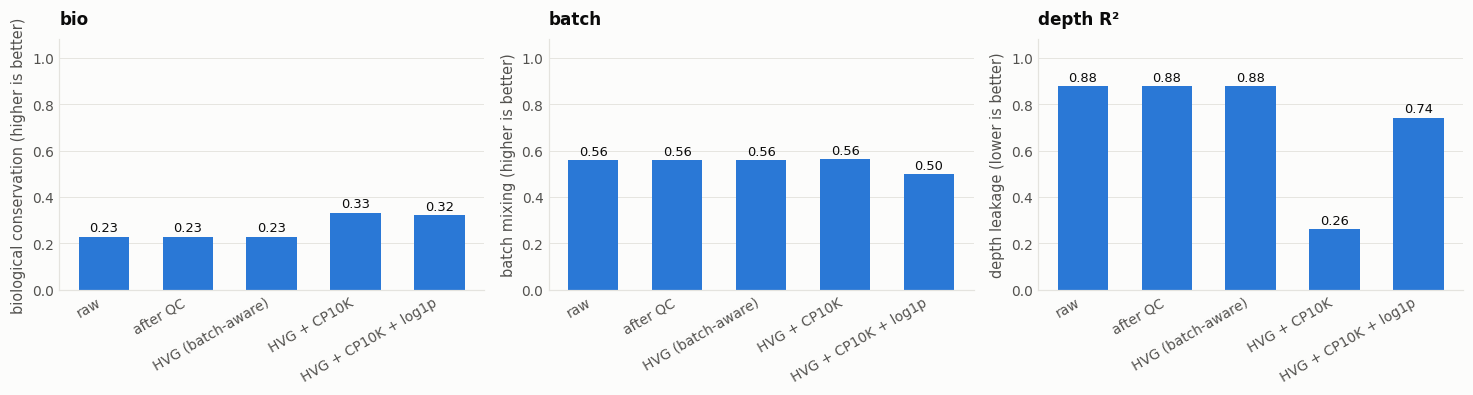

In [13]:
stages = {
    "raw": (X_raw, obs_raw),
    "after QC": (X, obs),
    "HVG (batch-aware)": (X[:, hvg_batch], obs),
    "HVG + CP10K": (normalize_counts(X[:, hvg_batch], log1p=False)[0], obs),
    "HVG + CP10K + log1p": (normalize_counts(X[:, hvg_batch])[0], obs),
}
rows = []
for name, (M, o) in stages.items():
    Z = pca(sp.csr_matrix(M).astype(np.float32), k=20)
    depth = np.asarray(X_raw.sum(1)).ravel() if name == "raw" else lib
    m = evaluate_embedding(Z, o["cell_type"], o["batch_id"], depth)
    rows.append({**describe(M if name in ("raw", "after QC", "HVG (batch-aware)") else X[:, hvg_batch], name),
                 "bio": m["bio_score"], "batch": m["batch_score"], "depth R²": m["library_size_r2"]})
stage_df = pd.DataFrame(rows).set_index("stage")

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.7))
for a, col, note in zip(ax, ["bio", "batch", "depth R²"],
                        ["biological conservation (higher is better)", "batch mixing (higher is better)",
                         "depth leakage (lower is better)"]):
    bars = a.bar(stage_df.index, stage_df[col], color=BLUE, width=0.6)
    a.set(title=col, ylabel=note, ylim=(0, 1.08))
    a.tick_params(axis="x", rotation=30)
    plt.setp(a.get_xticklabels(), ha="right")
    a.grid(axis="x", visible=False)
    label_bars(a, bars)
fig.tight_layout()
stage_df.round(3)

## What to carry forward

- QC removes many genes but almost no molecules.
- `log1p` rebalances variance across genes so a few abundant ones stop
  dominating.
- Depth scaling removes depth from the embedding; the log can bring some of
  it back. Watch `depth R²`, not just cell-type signal.
- The scoring flavor and batch-aware ranking change *which* genes are kept
  most when few genes are selected; with a generous `n_top` the strategies
  converge. Check the panels on your own data before trusting a default.
- A dataset that covers little of the vocabulary yields embeddings that are
  not comparable to the training corpus.
- In a training run, gene selection and every other fitted quantity use the
  **training split only**. Notebook **03** shows why and what it costs to
  get wrong.